# EDA: OSM Flock camera mapping history (2026-10-30 snapshot)

Personal exploratory analysis of `data/raw/flock_osm/flock_us_historical_2026-10-30.csv`,
following `docs/REPRODUCIBLE_EDA.md`.

**What one row means:** one row is **one camera** (one OSM node, the point a mapper
placed on the map). It is *not* one version of a camera and *not* one edit event.
Each row holds the camera's current state (`version`, `last_edit`, `changeset`, `user`)
plus a summary of its edit history, built by `scripts/fetch_osm_flock_history.py`:

- `first_insert_date` / `first_insert_version`: when the OSM node was first created.
- `first_tagged_date` / `first_tagged_version` / `first_tagged_changeset`: the first saved
  version whose tags matched the Flock ALPR rule (`man_made=surveillance`,
  `surveillance:type=ALPR`, `manufacturer` containing "Flock").
- `last_edit`: the most recent edit.

Step 1 checks this reading: every `osm_id` appears exactly once.

**None of these dates is an install date.** They record when volunteers *mapped* or
*tagged* a camera. Growth over time here means growth of the map, not of deployment.

- **Primary dataset:** the history file above. It is compared with the other primary file,
  `osm_flock_us_locations_2026-10-30.csv`, by `osm_id`.
- **Secondary dataset:** Census ACS 2020–2024 5-year tract estimates (population, median
  household income, race/ethnicity), joined through the 2024 TIGER/Line tract shapes.

Research questions (from `README.md`):
1. Where are mapped Flock cameras, and how has the mapping grown over time?
2. Is mapped camera density associated with community characteristics?
3. Is mapped camera density associated with political voting patterns?

In [1]:
from pathlib import Path
# Used to build file paths from the project root.

import geopandas as gpd
# Used to read census tract shapes and place each camera inside a tract.

import matplotlib.pyplot as plt
# Used to draw every plot.

import numpy as np
# Used for plot bins.

import pandas as pd
# Only needed to combine GeoPandas tables (GeoPandas is built on pandas).

import polars as pl
# Used for every table in this notebook.

from cs418_flock_research.loaders.load_osm_history import load_osm_history
# Project loader for this file: reads the raw CSV without cleaning it.

from cs418_flock_research.loaders.load_osm_locations import load_osm_locations
# Project loader for the locations file, used only for the comparison in 1B.

In [2]:
# Find the project root (the folder holding pyproject.toml), so the paths
# below work no matter which folder Jupyter was started from.
ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists():
    if ROOT == ROOT.parent:
        raise FileNotFoundError("Could not find pyproject.toml above the current folder.")
    ROOT = ROOT.parent

HISTORY_CSV = ROOT / "data" / "raw" / "flock_osm" / "flock_us_historical_2026-10-30.csv"
LOCATIONS_CSV = ROOT / "data" / "raw" / "flock_osm" / "osm_flock_us_locations_2026-10-30.csv"
ACS_DIR = ROOT / "data" / "raw" / "census"
POPULATION_CSV = ACS_DIR / "population" / "2024" / "ACSDT5Y2024.B01003-Data.csv"
INCOME_CSV = ACS_DIR / "median_household_income" / "2024" / "ACSDT5Y2024.B19013-Data.csv"
RACE_CSV = ACS_DIR / "race_ethnicity" / "2024" / "ACSDT5Y2024.B03002-Data.csv"
TRACT_DIR = ROOT / "data" / "external" / "census_boundaries" / "2024"

# Stop early with a clear message if any input is missing.
for input_path in [HISTORY_CSV, LOCATIONS_CSV, POPULATION_CSV, INCOME_CSV, RACE_CSV, TRACT_DIR]:
    if not input_path.exists():
        raise FileNotFoundError(f"Missing input: {input_path}")

# The two mapping periods compared in Step 4.
PERIOD_LABELS = ["Nov 2024 - Dec 2025", "Jan - Oct 2026"]

pl.Config.set_tbl_rows(30)
pl.Config.set_fmt_str_lengths(45)
pl.Config.set_tbl_width_chars(140)
plt.rcParams.update({"figure.figsize": (9, 5), "font.size": 11, "axes.titlesize": 13})
print("Project root:", ROOT)

Project root: C:\Users\awaid\OneDrive\Desktop\D\UIC\UIC_Fa26\CS418\cs418-flock-research


## Step 1: Dataset profile

### 1A. OSM mapping history (primary)

In [3]:
history = load_osm_history(HISTORY_CSV)
history.shape

(112527, 15)

**Observation:** The file has 112,527 rows and 15 columns.

In [4]:
# What is one row? If osm_id repeated, rows could be versions or edits of one
# camera (legitimate history). Check that before calling anything a duplicate.
row_count = history.height
unique_id_count = history["osm_id"].n_unique()
repeated_id_rows = history.filter(pl.col("osm_id").is_duplicated()).height
unique_row_count = history.unique().height
shared_spot_rows = history.filter(pl.struct("lat", "lon").is_duplicated()).height

print(f"Rows: {row_count:,}   unique osm_id: {unique_id_count:,}   rows with a repeated osm_id: {repeated_id_rows:,}")
print(f"Fully identical rows: {row_count - unique_row_count:,}")
print(f"Rows sharing exact coordinates with another row: {shared_spot_rows:,}")

Rows: 112,527   unique osm_id: 112,527   rows with a repeated osm_id: 0
Fully identical rows: 0
Rows sharing exact coordinates with another row: 1,865


**Observation:** Every `osm_id` appears exactly once (112,527 unique, 0 repeated), so one row is one camera, as the first cell says. There are no version or edit-event rows to separate, and no fully identical rows, so nothing needs dropping as a duplicate.

**Observation:** 1,865 rows share their exact coordinates with another row. Each has its own `osm_id`, so these are separate OSM nodes at one spot: several cameras on one pole, or one camera mapped twice. The data cannot tell which.

In [5]:
history.schema

Schema([('osm_id', String),
        ('lat', Float64),
        ('lon', Float64),
        ('manufacturer', String),
        ('operator', String),
        ('version', Int64),
        ('last_edit', String),
        ('changeset', Int64),
        ('user', String),
        ('history_ok', Boolean),
        ('first_insert_date', String),
        ('first_insert_version', Int64),
        ('first_tagged_date', String),
        ('first_tagged_version', Int64),
        ('first_tagged_changeset', Int64)])

**Observation:** `osm_id` is text (from the loader) and the version and changeset columns are whole numbers, which fits. The three date columns are text and are parsed below. `history_ok` is a true/false column.

In [6]:
history.head(5)

osm_id,lat,lon,manufacturer,operator,version,last_edit,changeset,user,history_ok,first_insert_date,first_insert_version,first_tagged_date,first_tagged_version,first_tagged_changeset
str,f64,f64,str,str,i64,str,i64,str,bool,str,i64,str,i64,i64
"""31431226""",35.161641,-101.920186,"""Flock Safety""","""Amarillo Police Department""",6,"""2024-12-27T22:33:51.000000+0000""",160695327,"""WutTheFlock""",true,"""2012-07-18T15:17:14.000000+0000""",3,"""2024-12-27T22:33:51.000000+0000""",6,160695327
"""41878496""",33.030454,-112.647828,"""Flock Safety""",null,5,"""2025-12-11T04:26:19.000000+0000""",175784926,"""MapsterJay""",true,"""2007-09-05T12:27:31.000000+0000""",1,"""2025-12-11T04:26:19.000000+0000""",5,175784926
"""51080371""",40.627144,-105.138128,"""Flock Safety""","""Larimer County Sheriff's Office""",5,"""2026-09-17T17:39:29.000000+0000""",189174748,"""spencer0""",true,"""2007-09-14T05:31:36.000000+0000""",1,"""2026-09-17T17:39:29.000000+0000""",5,189174748
"""51968727""",30.275525,-87.683088,"""Flock Safety""",null,4,"""2026-05-20T13:18:56.000000+0000""",182928120,"""Spyder_Monkey""",true,"""2007-09-15T11:13:54.000000+0000""",1,"""2026-03-24T15:20:50.000000+0000""",3,180359785
"""53092228""",37.823138,-122.217199,"""Flock Safety""","""Piedmont""",17,"""2026-09-17T23:58:04.000000+0000""",189185542,"""Mapper17582948""",true,"""2007-09-17T06:06:19.000000+0000""",1,"""2025-12-19T05:08:05.000000+0000""",16,176122658


In [7]:
# Nulls and blank strings ("") per column.
missing_rows = []
for column_name, dtype in history.schema.items():
    blank_count = 0
    if dtype == pl.String:
        blank_count = history.filter(pl.col(column_name).str.strip_chars() == "").height
    missing_rows.append({"column": column_name, "nulls": history[column_name].null_count(), "blank_strings": blank_count})
missing_table = (
    pl.DataFrame(missing_rows)
    .with_columns((pl.col("nulls") / row_count * 100).round(1).alias("null_pct"))
    .sort("nulls", descending=True)
)
missing_table

column,nulls,blank_strings,null_pct
str,i64,i64,f64
"""operator""",98711,0,87.7
"""osm_id""",0,0,0.0
"""lat""",0,0,0.0
"""lon""",0,0,0.0
"""manufacturer""",0,0,0.0
"""version""",0,0,0.0
"""last_edit""",0,0,0.0
"""changeset""",0,0,0.0
"""user""",0,0,0.0


**Observation:** The only column with gaps is `operator`, missing for 98,711 cameras (87.7%). All date and version columns are complete.

In [8]:
# history_ok is False when the script found no history for a camera.
history["history_ok"].value_counts()

history_ok,count
bool,u32
true,112527


**Observation:** `history_ok` is true for all 112,527 cameras, so the download finished; this is the final file, not an `_INCOMPLETE` one.

In [9]:
history.select("version", "first_insert_version", "first_tagged_version", "lat", "lon").describe()

statistic,version,first_insert_version,first_tagged_version,lat,lon
str,f64,f64,f64,f64,f64
"""count""",112527.0,112527.0,112527.0,112527.0,112527.0
"""null_count""",0.0,0.0,0.0,0.0,0.0
"""mean""",1.29752,1.000018,1.046549,36.209724,-93.776455
"""std""",0.670924,0.005962,0.280984,4.82333,14.601063
"""min""",1.0,1.0,1.0,17.697551,-158.123622
"""25%""",1.0,1.0,1.0,33.043349,-98.631885
"""50%""",1.0,1.0,1.0,35.837116,-88.878555
"""75%""",1.0,1.0,1.0,39.948588,-83.160181
"""max""",17.0,3.0,16.0,61.613915,-64.632441


**Observation:** Most cameras were never edited after being placed: median `version` 1, maximum 17. `first_tagged_version` is also 1 for at least three quarters of cameras (max 16), so most nodes were tagged as Flock cameras the moment they were created.

In [10]:
# Placeholder check: a first version that is not 1 means the earliest versions
# were not returned, so first_insert_date may be too late for that camera.
history["first_insert_version"].value_counts(sort=True)

first_insert_version,count
i64,u32
1,112526
3,1


**Observation:** One camera's first returned version is 3, not 1, so its two earliest versions are missing and its `first_insert_date` may be later than the real creation date.

In [11]:
history["manufacturer"].value_counts(sort=True).head(8)

manufacturer,count
str,u32
"""Flock Safety""",111931
"""Flock Group Inc.""",477
"""Flock""",57
"""Flock Safety Inc""",44
"""FlockSafety""",4
"""flock""",3
"""Flock Safety;Motorola Solutions""",2
"""Flock Surveillance""",2


**Observation:** 111,931 cameras say exactly `Flock Safety`; the rest are spelling variants such as `Flock Group Inc.` (477). All contain "Flock" because of the tag rule.

In [12]:
print(f"Distinct mappers (user of the last edit): {history['user'].n_unique():,}")
history["user"].value_counts(sort=True).head(5)

Distinct mappers (user of the last edit): 24,192


user,count
str,u32
"""a_bro""",2612
"""emersonveenstra""",1677
"""palmdale_sucks""",720
"""Flnative""",665
"""Motor City Elevator Co""",552


**Observation:** 24,192 different mappers made the most recent edit. The most active, `a_bro`, last edited 2,612 cameras.

**Time.** The three date columns are text like `2025-12-11T04:26:19.000000+0000`.
They are parsed into UTC datetimes below. This adds columns to the table in memory;
the raw file is untouched.

In [13]:
DATE_FORMAT = "%Y-%m-%dT%H:%M:%S%.f%z"
history = history.with_columns(
    pl.col("first_insert_date").str.to_datetime(DATE_FORMAT).alias("inserted"),
    pl.col("first_tagged_date").str.to_datetime(DATE_FORMAT).alias("tagged"),
    pl.col("last_edit").str.to_datetime(DATE_FORMAT).alias("edited"),
)
date_ranges = pl.DataFrame({
    "column": ["first_insert_date", "first_tagged_date", "last_edit"],
    "unparsed": [history[c].null_count() for c in ["inserted", "tagged", "edited"]],
    "earliest": [str(history[c].min()) for c in ["inserted", "tagged", "edited"]],
    "latest": [str(history[c].max()) for c in ["inserted", "tagged", "edited"]],
})
date_ranges

column,unparsed,earliest,latest
str,i64,str,str
"""first_insert_date""",0,"""2007-09-05 12:27:31+00:00""","""2026-10-30 19:32:28+00:00"""
"""first_tagged_date""",0,"""2024-11-03 03:04:15+00:00""","""2026-10-30 19:32:28+00:00"""
"""last_edit""",0,"""2024-11-17 02:09:40+00:00""","""2026-10-30 19:32:28+00:00"""


**Observation:** All three date columns parse with 0 failures. `first_insert_date` reaches back to 2007, but `first_tagged_date` starts on 2024-11-03 and `last_edit` on 2024-11-17. All three end at 2026-10-30 19:32 UTC.

In [14]:
# Rows per year for each date column, side by side.
years_inserted = history.group_by(pl.col("inserted").dt.year().alias("year")).len("first_inserted")
years_tagged = history.group_by(pl.col("tagged").dt.year().alias("year")).len("first_tagged")
years_edited = history.group_by(pl.col("edited").dt.year().alias("year")).len("last_edited")
rows_per_year = (
    years_inserted.join(years_tagged, on="year", how="full", coalesce=True)
    .join(years_edited, on="year", how="full", coalesce=True)
    .fill_null(0)
    .sort("year")
)
rows_per_year

year,first_inserted,first_tagged,last_edited
i32,u32,u32,u32
2007,36,0,0
2008,8,0,0
2009,6,0,0
2010,9,0,0
2011,5,0,0
2012,24,0,0
2013,11,0,0
2014,8,0,0
2015,6,0,0


**Observation:** Some nodes are old: 36 were created in 2007, and 657 before November 2024. Almost all (42,009 in 2025 and 67,599 in 2026) are recent.

**Observation:** By first-tagged year there are only three years: 1,301 cameras in 2024 (two months), 42,325 in 2025 and 68,901 in 2026 (ten months).

In [15]:
# Rows per month of first_tagged_date, the closest thing to "date first mapped as a Flock camera".
tagged_by_month = history.group_by(pl.col("tagged").dt.truncate("1mo").alias("month")).len("cameras").sort("month")

# A gap is a calendar month with no camera between the first and last month.
all_months = pl.datetime_range(tagged_by_month["month"].min(), tagged_by_month["month"].max(), "1mo", eager=True, time_zone="UTC")
print(f"Months covered: {tagged_by_month.height}   calendar months in that span: {all_months.len()}   empty months: {all_months.len() - tagged_by_month.height}")
tagged_by_month

Months covered: 24   calendar months in that span: 24   empty months: 0


month,cameras
"datetime[μs, UTC]",u32
2024-11-01 00:00:00 UTC,514
2024-12-01 00:00:00 UTC,787
2025-01-01 00:00:00 UTC,1856
2025-02-01 00:00:00 UTC,1421
2025-03-01 00:00:00 UTC,1438
2025-04-01 00:00:00 UTC,2402
2025-05-01 00:00:00 UTC,1769
2025-06-01 00:00:00 UTC,1955
2025-07-01 00:00:00 UTC,1765


**Observation:** There are no gaps: all 24 calendar months from November 2024 to October 2026 have cameras.

**Observation:** There are two spikes. November 2025 jumps to 9,345 from 4,434 the month before, and July and August 2026 reach 11,457 and 11,807 before falling to 4,884 in September. Step 4 checks whether bulk uploads cause them.

**Collection artifacts.** These checks look for patterns caused by how the data was
collected (the tag rule, the script, the download date), not by real mapping or installs.

In [16]:
# 1) No date before November 2024 in first_tagged_date or last_edit, even though
#    some nodes were created years earlier.
created_before = history.filter(pl.col("inserted") < pl.datetime(2024, 11, 1, time_zone="UTC")).height
print(f"Nodes created before 2024-11-01: {created_before:,}")
print(f"Earliest first_tagged_date: {history['tagged'].min()}   earliest last_edit: {history['edited'].min()}")

Nodes created before 2024-11-01: 657
Earliest first_tagged_date: 2024-11-03 03:04:15+00:00   earliest last_edit: 2024-11-17 02:09:40+00:00


**Observation:** 657 nodes were created before 1 November 2024, yet no camera has a first-tagged date before 2024-11-03 or a last edit before 2024-11-17. Every older node met the tag rule only later. The start of every time series here is therefore set by tagging, not by when mapping began. The data does not show why; it could be a tagging convention that changed around then.

In [17]:
# 2) Never-edited nodes (version 1) get the same value for all three dates, by
#    construction in the script (no history request is made for them).
version_one = history.filter(pl.col("version") == 1)
all_dates_equal = version_one.filter(
    (pl.col("inserted") == pl.col("tagged")) & (pl.col("tagged") == pl.col("edited"))
).height
print(f"Version-1 cameras: {version_one.height:,} ({version_one.height / row_count * 100:.1f}%)   with all three dates equal: {all_dates_equal:,}")
print(f"Cameras tagged later than created: {history.filter(pl.col('tagged') > pl.col('inserted')).height:,}")
print(f"Cameras tagged before created (impossible): {history.filter(pl.col('tagged') < pl.col('inserted')).height}")
print(f"Cameras tagged after their last edit (impossible): {history.filter(pl.col('tagged') > pl.col('edited')).height}")

Version-1 cameras: 88,391 (78.6%)   with all three dates equal: 88,391
Cameras tagged later than created: 3,876
Cameras tagged before created (impossible): 0
Cameras tagged after their last edit (impossible): 0


**Observation:** 88,391 cameras (78.6%) are version 1, and all of them have the same value in all three date columns. This comes from the script, which copies the snapshot date for never-edited nodes instead of asking the API.

**Observation:** 3,876 cameras were tagged later than their node was created (existing points that became Flock cameras). No camera is tagged before creation or after its last edit, so the dates are internally consistent.

In [18]:
# 3) The last month is partial: the newest date shows when the download stopped.
print(f"Newest date in the file: {history['edited'].max()}")
print(f"Days of October 2026 covered: {history['edited'].max().day}")

Newest date in the file: 2026-10-30 19:32:28+00:00
Days of October 2026 covered: 30


**Observation:** The newest date is 2026-10-30 19:32 UTC, so October 2026 covers only 30 days and stops mid-day. Its low count (2,737) is partly the cut-off, not a real slowdown.

In [19]:
# 4) Bulk uploads: how many cameras were first tagged in the same changeset
#    (one upload by one mapper)?
changeset_sizes = history.group_by("first_tagged_changeset").len("cameras_in_changeset")
history = history.join(changeset_sizes, on="first_tagged_changeset", how="left", validate="m:1")
print(f"Distinct first-tagged changesets: {changeset_sizes.height:,}")
print(f"Cameras whose changeset tagged 50+ cameras: {history.filter(pl.col('cameras_in_changeset') >= 50).height:,}")
changeset_sizes.sort("cameras_in_changeset", descending=True).head(5)

Distinct first-tagged changesets: 94,928
Cameras whose changeset tagged 50+ cameras: 1,234


first_tagged_changeset,cameras_in_changeset
i64,u32
159351933,430
162448054,291
181158498,106
167932750,101
173339234,69


**Observation:** 112,527 cameras came in 94,928 different first-tagged changesets (uploads). Only 1,234 cameras came in uploads of 50 or more; the largest single upload tagged 430.

**Geography check.** Coordinates are WGS 84 latitude/longitude (EPSG:4326). Each camera
is placed inside a 2024 census tract (50 states + DC).

In [20]:
# Read the 51 state tract files (only GEOID is needed) and stack them.
tract_frames = [gpd.read_file(path, columns=["GEOID"]) for path in sorted(TRACT_DIR.glob("tl_2024_*_tract.zip"))]
tract_shapes = gpd.GeoDataFrame(pd.concat(tract_frames, ignore_index=True), crs=tract_frames[0].crs)

# Match the tracts' coordinate system (NAD83) before joining.
camera_points = gpd.GeoDataFrame(
    history.select("osm_id", "lat", "lon").to_pandas(),
    geometry=gpd.points_from_xy(history["lon"].to_numpy(), history["lat"].to_numpy()),
    crs="EPSG:4326",
).to_crs(tract_shapes.crs)

# "within": the tract that contains each point. how="left" keeps unmatched cameras.
camera_tract_join = gpd.sjoin(camera_points, tract_shapes, how="left", predicate="within")
camera_tracts = pl.from_pandas(camera_tract_join[["osm_id", "lat", "lon", "GEOID"]])

print(f"Tract shapes: {len(tract_shapes):,}   CRS: {tract_shapes.crs}")
print(f"Camera rows before join: {history.height:,}   after join: {camera_tracts.height:,}")
print(f"Matched to a tract: {camera_tracts['GEOID'].is_not_null().sum():,}   in no tract: {camera_tracts['GEOID'].is_null().sum():,}")
camera_tracts.filter(pl.col("GEOID").is_null()).with_columns(
    pl.when((pl.col("lat") < 19) & (pl.col("lon") > -68))
    .then(pl.lit("Puerto Rico / U.S. Virgin Islands area"))
    .otherwise(pl.lit("elsewhere"))
    .alias("area")
).group_by("area").len("cameras").sort("area")

Tract shapes: 84,415   CRS: EPSG:4269
Camera rows before join: 112,527   after join: 112,527
Matched to a tract: 112,322   in no tract: 205


area,cameras
str,u32
"""Puerto Rico / U.S. Virgin Islands area""",199
"""elsewhere""",6


**Observation:** The join keeps all 112,527 rows. 112,322 cameras fall in a tract; 199 of the 205 that don't are in the Puerto Rico / U.S. Virgin Islands area, outside the 50-state + DC shapes.

In [21]:
# Raw vs. loaded: the default read guesses types from the first 100 rows only.
try:
    raw_default = pl.read_csv(HISTORY_CSV)
    print("Default read: succeeded")
    print("Columns whose type differs from the loader:",
          [c for c in raw_default.columns if raw_default.schema[c] != load_osm_history(HISTORY_CSV).schema[c]])
    print("osm_id type  default:", raw_default.schema["osm_id"], "  loader:", load_osm_history(HISTORY_CSV).schema["osm_id"])
except pl.exceptions.ComputeError as error:
    print("Default read failed:", str(error).splitlines()[0])

Default read: succeeded


Columns whose type differs from the loader: ['osm_id']


osm_id type  default: Int64   loader: String


**Observation:** Unlike the locations file, this file reads with Polars defaults. The only difference is `osm_id`, which the loader keeps as text instead of a number.

### 1B. How this file relates to the locations file

In [22]:
# Compare by osm_id: the two files come from separate downloads.
locations = load_osm_locations(LOCATIONS_CSV)
history_ids = history.select("osm_id")
location_ids = locations.select("osm_id")

in_both = history_ids.join(location_ids, on="osm_id", how="semi").height
history_only = history.join(location_ids, on="osm_id", how="anti")
locations_only = locations.join(history_ids, on="osm_id", how="anti")
print(f"History rows: {history.height:,}   locations rows: {locations.height:,}")
print(f"In both: {in_both:,}   history only: {history_only.height:,}   locations only: {locations_only.height:,}")

History rows: 112,527   locations rows: 112,830
In both: 112,124   history only: 403   locations only: 706


**Observation:** 112,124 cameras are in both files. 403 are only in the history file and 706 only in the locations file, so the two downloads differ by about 1%.

In [23]:
# Locations-only cameras: when were they last edited? The history file's newest
# date is the cut-off of its download.
history_cutoff = history["last_edit"].max()
print(f"History cut-off: {history_cutoff}")
print(f"Locations-only cameras last edited after 2026-10-30T19:32:28: "
      f"{locations_only.filter(pl.col('timestamp') > '2026-10-30T19:32:28Z').height:,} of {locations_only.height:,}")
locations_only.group_by(pl.col("timestamp").str.slice(0, 10).alias("last_edit_day")).len("cameras").sort("last_edit_day").tail(8)

History cut-off: 2026-10-30T19:32:28.000000+0000
Locations-only cameras last edited after 2026-10-30T19:32:28: 706 of 706


last_edit_day,cameras
str,u32
"""2026-10-30""",87
"""2026-10-31""",210
"""2026-11-01""",73
"""2026-11-02""",80
"""2026-11-03""",75
"""2026-11-04""",100
"""2026-11-05""",81


**Observation:** All 706 locations-only cameras were last edited after the history cut-off (2026-10-30 19:32 UTC), running to 2026-11-05. They were mapped or edited after the history download, which confirms the locations file was pulled about a week later than its name says.

In [24]:
# History-only cameras: in the history pull but gone from the later locations pull
# (deleted, moved off the tag rule, or retagged). Their last edits:
history_only.group_by(pl.col("tagged").dt.year().alias("first_tagged_year")).len("cameras").sort("first_tagged_year")

first_tagged_year,cameras
i32,u32
2024,1
2025,112
2026,290


**Observation:** The 403 history-only cameras were mostly first tagged in 2026 (290). They left the map between the two downloads: deleted, retagged, or edited so they no longer match the rule.

In [25]:
# Shared cameras: did they change between the two downloads?
shared = history.join(
    locations.select("osm_id", pl.col("version").alias("locations_version"), pl.col("lat").alias("locations_lat"), pl.col("lon").alias("locations_lon")),
    on="osm_id", how="inner", validate="1:1",
)
print(f"Shared cameras: {shared.height:,}")
print(f"Newer version in the locations file: {shared.filter(pl.col('locations_version') > pl.col('version')).height:,}")
print(f"Older version in the locations file: {shared.filter(pl.col('locations_version') < pl.col('version')).height:,}")
print(f"Coordinates changed: {shared.filter((pl.col('lat') != pl.col('locations_lat')) | (pl.col('lon') != pl.col('locations_lon'))).height:,}")

Shared cameras: 112,124
Newer version in the locations file: 136
Older version in the locations file: 0
Coordinates changed: 70


**Observation:** Of the 112,124 shared cameras, 136 have a newer version in the locations file (never an older one) and 70 moved. That fits a few days of ordinary editing between the downloads.

### 1C. Census ACS 2024 tracts (secondary)

Profiled only because Step 4 uses it. Each `Data.csv` has two header rows (codes, then
labels). Values are read as text first so codes keep leading zeros and placeholders can be counted.

In [26]:
def read_acs_table(path: Path, estimate_columns: list[str]) -> pl.DataFrame:
    """Read one ACS Data.csv as text, skipping the second header row of labels."""
    table = pl.read_csv(path, infer_schema=False, skip_rows_after_header=1)
    # GEO_ID looks like "1400000US01001020100"; the last 11 characters are the tract GEOID.
    return table.select(pl.col("GEO_ID").str.slice(-11).alias("GEOID"), pl.col("NAME"), *estimate_columns)


acs_population = read_acs_table(POPULATION_CSV, ["B01003_001E"])
acs_income = read_acs_table(INCOME_CSV, ["B19013_001E"])
acs_race = read_acs_table(RACE_CSV, ["B03002_001E", "B03002_003E"])
for table_name, table in [("population", acs_population), ("income", acs_income), ("race", acs_race)]:
    print(f"{table_name:<11} shape {table.shape}   unique GEOID {table['GEOID'].n_unique():,}   "
          f"GEOID always 11 chars: {(table['GEOID'].str.len_chars() == 11).all()}")
income_text = acs_income["B19013_001E"]
population_text = acs_population["B01003_001E"]
print("Income values that are not plain numbers:")
income_text.filter(~income_text.str.contains(r"^\d+$")).value_counts(sort=True)

population  shape (85382, 3)   unique GEOID 85,382   GEOID always 11 chars: True
income      shape (85382, 3)   unique GEOID 85,382   GEOID always 11 chars: True
race        shape (85382, 4)   unique GEOID 85,382   GEOID always 11 chars: True
Income values that are not plain numbers:


B19013_001E,count
str,u32
"""-""",1554
"""250,000+""",553
"""2,500-""",9


**Observation:** Each ACS table has 85,382 tracts with unique 11-character `GEOID`s, so leading zeros are kept. Median income uses placeholders: 1,554 `-` (no estimate), 553 `250,000+` and 9 `2,500-`.

In [27]:
print("Tracts with population 0:", (population_text == "0").sum())

# One tract table: population, median income (caps set to the cap value,
# "-" to null), and non-Hispanic white share.
tracts = (
    acs_population.select(
        "GEOID",
        pl.col("NAME").str.split("; ").list.last().alias("state"),
        pl.col("B01003_001E").cast(pl.Int64).alias("population"),
    )
    .join(
        acs_income.select(
            "GEOID",
            pl.when(pl.col("B19013_001E") == "250,000+").then(pl.lit("250000"))
            .when(pl.col("B19013_001E") == "2,500-").then(pl.lit("2500"))
            .when(pl.col("B19013_001E") == "-").then(None)
            .otherwise(pl.col("B19013_001E"))
            .cast(pl.Float64)
            .alias("median_income"),
        ),
        on="GEOID", how="left", validate="1:1",
    )
    .join(
        acs_race.select(
            "GEOID",
            pl.col("B03002_001E").cast(pl.Int64).alias("race_total"),
            pl.col("B03002_003E").cast(pl.Int64).alias("white_non_hispanic"),
        ),
        on="GEOID", how="left", validate="1:1",
    )
    .with_columns(
        pl.when(pl.col("race_total") > 0)
        .then(pl.col("white_non_hispanic") / pl.col("race_total") * 100)
        .alias("white_share_pct")
    )
)
print(f"ACS tracts: {tracts.height:,}")

Tracts with population 0: 853


ACS tracts: 85,382

**Join setup.** Attach each camera's tract and mapping period, then count cameras per
tract for each period. Tracts with no camera get 0, a real value that stays in the rates.
Puerto Rico is dropped because the tract shapes cover only the 50 states and DC.

In [28]:
shape_geoids = pl.DataFrame({"GEOID": tract_shapes["GEOID"].to_list()})
cameras_located = (
    history.join(camera_tracts.select("osm_id", "GEOID"), on="osm_id", how="left", validate="1:1")
    .filter(pl.col("GEOID").is_not_null())
    .with_columns(
        pl.when(pl.col("tagged") < pl.datetime(2026, 1, 1, time_zone="UTC"))
        .then(pl.lit(PERIOD_LABELS[0]))
        .otherwise(pl.lit(PERIOD_LABELS[1]))
        .alias("period")
    )
)
counts_per_tract = cameras_located.group_by("GEOID").agg(
    pl.len().alias("cameras"),
    (pl.col("period") == PERIOD_LABELS[0]).sum().alias("cameras_before_2026"),
    (pl.col("period") == PERIOD_LABELS[1]).sum().alias("cameras_2026"),
)
tracts_before = tracts.height
tract_cameras = (
    tracts.join(shape_geoids, on="GEOID", how="semi")
    .join(counts_per_tract, on="GEOID", how="left", validate="1:1")
    .with_columns(pl.col("cameras", "cameras_before_2026", "cameras_2026").fill_null(0))
)
print(f"ACS tracts before: {tracts_before:,}   after keeping tracts with a shape: {tract_cameras.height:,}")
print("Dropped ACS tracts by state:", tracts.join(shape_geoids, on="GEOID", how="anti")["state"].value_counts().rows())
print(f"Cameras with a tract: {cameras_located.height:,}   counted in the tract table: {tract_cameras['cameras'].sum():,}")

ACS tracts before: 85,382   after keeping tracts with a shape: 84,401
Dropped ACS tracts by state: [('Puerto Rico', 981)]
Cameras with a tract: 112,322   counted in the tract table: 112,320


**Observation:** Keeping tracts with a shape drops 981 ACS rows, all in Puerto Rico. 112,322 cameras have a tract and 112,320 are counted; the other 2 fall in tracts that have a shape but no ACS row.

## Step 2: Anomalies

Every count is computed from outputs above. "What I did" applies to this notebook only;
the raw files are never changed.

In [29]:
anomalies = pl.DataFrame(
    [
        ("History", "Repeated `osm_id` (would be legitimate history rows)", repeated_id_rows, "Left and flagged (none found)"),
        ("History", "Fully identical rows", row_count - unique_row_count, "Left and flagged (none found)"),
        ("History", "Rows sharing exact coordinates with another row", shared_spot_rows, "Left and flagged (can be several cameras on one pole)"),
        ("History", "`operator` missing", missing_table.filter(pl.col("column") == "operator")["nulls"].item(), "Left and flagged"),
        ("History", "`manufacturer` spelling variants of Flock Safety", history.filter(pl.col("manufacturer") != "Flock Safety").height, "Left and flagged (all are Flock)"),
        ("History", "`first_insert_version` is not 1 (early versions missing)", history.filter(pl.col("first_insert_version") != 1).height, "Left and flagged"),
        ("History", "No first-tagged or last-edit date before Nov 2024, though nodes are older", created_before, "Left and flagged (cause not found in the data)"),
        ("History", "Version-1 cameras: all three dates equal by construction", all_dates_equal, "Left and flagged"),
        ("History", "Dates stored as text with a +0000 offset", row_count, "Fixed (parsed to UTC datetimes in memory)"),
        ("History", "October 2026 is a partial month (download cut-off)", history.filter(pl.col("tagged") >= pl.datetime(2026, 10, 1, time_zone="UTC")).height, "Left and flagged"),
        ("History", "Cameras outside the 50-state + DC tract shapes", camera_tracts["GEOID"].is_null().sum(), "Dropped the rows (from the ACS join only)"),
        ("History vs. locations", "In history only (gone from the later pull)", history_only.height, "Left and flagged"),
        ("History vs. locations", "In locations only (added after the history cut-off)", locations_only.height, "Left and flagged"),
        ("ACS", "Median income '-' (no estimate)", (income_text == "-").sum(), "Dropped the rows (from income plots only)"),
        ("ACS", "Median income capped ('250,000+' or '2,500-')", income_text.is_in(["250,000+", "2,500-"]).sum(), "Fixed (set to the cap value)"),
        ("ACS", "Tracts with population 0", (population_text == "0").sum(), "Dropped the rows (from per-resident rates)"),
        ("ACS", "Puerto Rico tracts with no tract shape", tracts_before - tract_cameras.height, "Dropped the rows"),
    ],
    schema=["Dataset", "Anomaly", "Rows affected", "What I did"],
    orient="row",
)
with pl.Config(fmt_str_lengths=80, tbl_width_chars=200, tbl_rows=30):
    print(anomalies)

shape: (17, 4)
┌───────────────────────┬───────────────────────────────────────────────────────────────────────────┬───────────────┬───────────────────────────────────────────────────────┐
│ Dataset               ┆ Anomaly                                                                   ┆ Rows affected ┆ What I did                                            │
│ ---                   ┆ ---                                                                       ┆ ---           ┆ ---                                                   │
│ str                   ┆ str                                                                       ┆ i64           ┆ str                                                   │
╞═══════════════════════╪═══════════════════════════════════════════════════════════════════════════╪═══════════════╪═══════════════════════════════════════════════════════╡
│ History               ┆ Repeated `osm_id` (would be legitimate history rows)                      ┆ 0            

**Observation:** The anomalies that matter most for research question 1 are about *time*: the start of the series in November 2024 (657 older nodes) and the partial October 2026 (2,737 cameras) come from how the data was collected, not from real mapping or installs.

## Step 3: Distributions

One plot per feature that matters to the research questions.

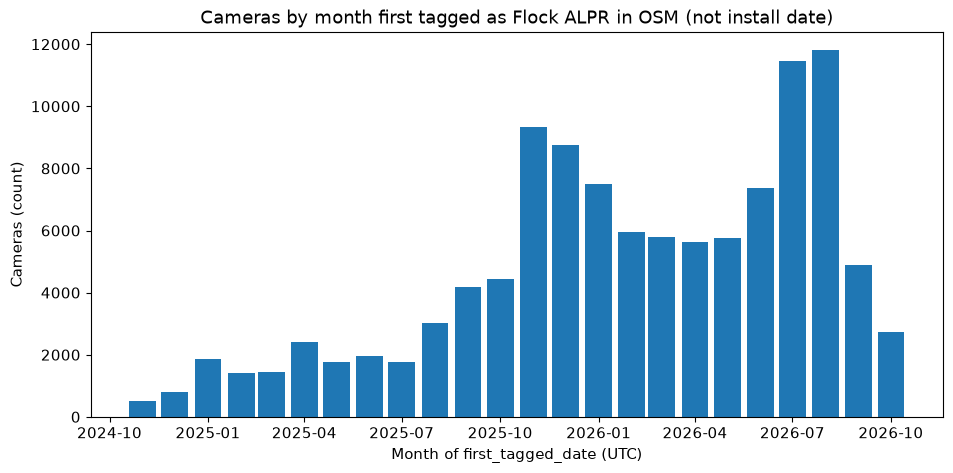

Median first-tagged date: 2026-02-24 00:00:00
Middle 50%: 2025-11-13 00:00:00 to 2026-07-09 00:00:00


In [30]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(tagged_by_month["month"].to_list(), tagged_by_month["cameras"].to_list(), width=25, color="tab:blue")
ax.set_title("Cameras by month first tagged as Flock ALPR in OSM (not install date)")
ax.set_xlabel("Month of first_tagged_date (UTC)")
ax.set_ylabel("Cameras (count)")
plt.show()
tagged_days = history["tagged"].dt.date()
print(f"Median first-tagged date: {tagged_days.median()}")
print(f"Middle 50%: {tagged_days.quantile(0.25)} to {tagged_days.quantile(0.75)}")

**Observation (center and spread):** The median camera was first tagged on 2026-02-24, and the middle half between 2025-11-13 and 2026-07-09.

**Observation (skew and outliers):** Monthly counts rise over time with two outlying spikes (November 2025 and July-August 2026). The first two months and October 2026 are low because of collection limits (see Step 1).

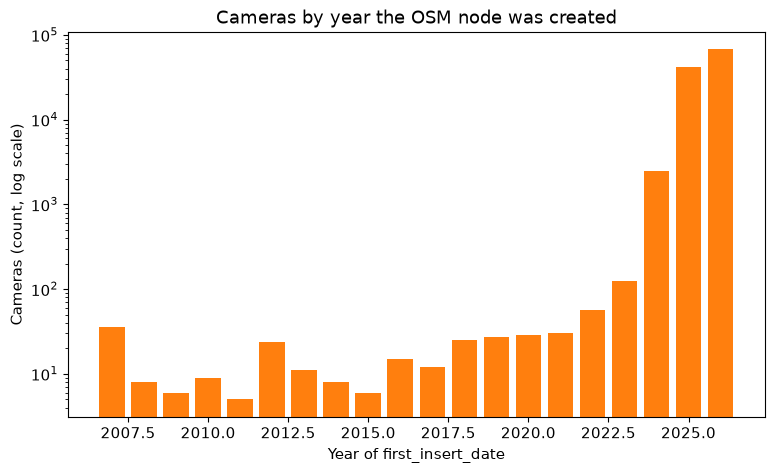

Nodes created in 2025-2026: 97.4%


In [31]:
# Year each OSM node was created. Log scale because a few nodes are very old.
fig, ax = plt.subplots()
ax.bar(rows_per_year["year"], rows_per_year["first_inserted"], color="tab:orange")
ax.set_yscale("log")
ax.set_title("Cameras by year the OSM node was created")
ax.set_xlabel("Year of first_insert_date")
ax.set_ylabel("Cameras (count, log scale)")
plt.show()
print(f"Nodes created in 2025-2026: {history.filter(pl.col('inserted').dt.year() >= 2025).height / row_count * 100:.1f}%")

**Observation:** 97.4% of nodes were created in 2025-2026; the bars before 2024 are tiny on a log scale. Node creation and first tagging tell almost the same story.

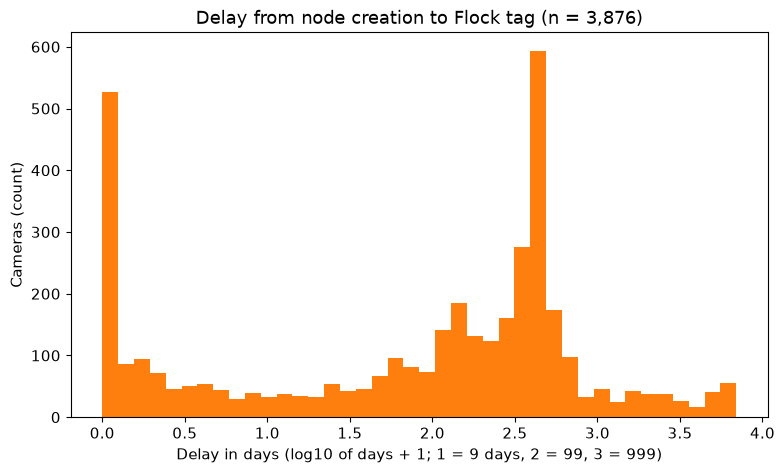

Median delay: 154.8 days   middle 50%: 4.9 to 429.3 days
Delays over 1 year: 1,268   longest: 19.0 years
Tagged within 1 day of creation: 720   tagged 200-600 days after creation: 1,321


In [32]:
# For cameras tagged later than created: how long did the node exist first?
lag_days = (
    history.filter(pl.col("tagged") > pl.col("inserted"))
    .select(((pl.col("tagged") - pl.col("inserted")).dt.total_seconds() / 86_400).alias("days"))["days"]
)
fig, ax = plt.subplots()
ax.hist(np.log10(lag_days.to_numpy() + 1), bins=40, color="tab:orange")
ax.set_title(f"Delay from node creation to Flock tag (n = {lag_days.len():,})")
ax.set_xlabel("Delay in days (log10 of days + 1; 1 = 9 days, 2 = 99, 3 = 999)")
ax.set_ylabel("Cameras (count)")
plt.show()
print(f"Median delay: {lag_days.median():.1f} days   middle 50%: {lag_days.quantile(0.25):.1f} to {lag_days.quantile(0.75):.1f} days")
print(f"Delays over 1 year: {(lag_days > 365).sum():,}   longest: {lag_days.max() / 365:.1f} years")
print(f"Tagged within 1 day of creation: {(lag_days < 1).sum():,}   tagged 200-600 days after creation: {lag_days.is_between(200, 600).sum():,}")

**Observation (center and spread):** For the 3,876 cameras tagged after creation, the median delay is 154.8 days, and the middle half spans 4.9 to 429.3 days, a very wide spread.

**Observation (skew and outliers):** The delay has two peaks: 720 cameras were tagged within a day (a quick fix after placing the point) and 1,321 between 200 and 600 days later. 1,268 waited over a year, and the longest wait is 19.0 years: old points re-tagged as Flock cameras.

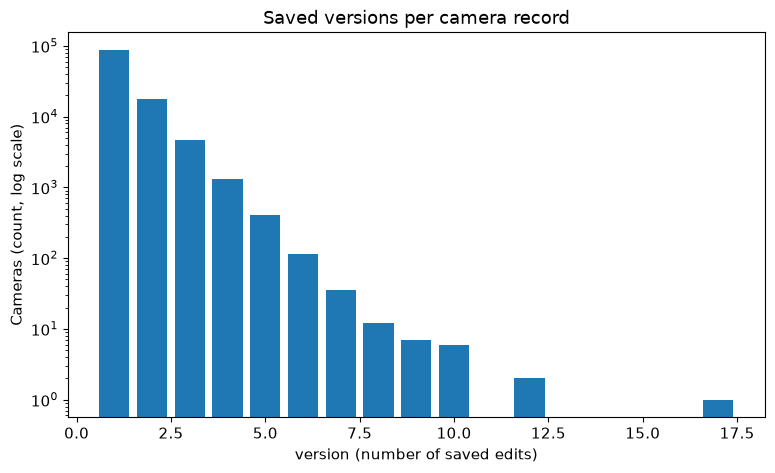

Median version: 1   mean: 1.30   max: 17
Version 1: 78.6%   version 5+: 577


In [33]:
# Number of saved versions per camera (how often each record was edited).
version_counts = history["version"].value_counts().sort("version")
fig, ax = plt.subplots()
ax.bar(version_counts["version"], version_counts["count"], color="tab:blue")
ax.set_yscale("log")
ax.set_title("Saved versions per camera record")
ax.set_xlabel("version (number of saved edits)")
ax.set_ylabel("Cameras (count, log scale)")
plt.show()
print(f"Median version: {history['version'].median():.0f}   mean: {history['version'].mean():.2f}   max: {history['version'].max()}")
print(f"Version 1: {(history['version'] == 1).mean() * 100:.1f}%   version 5+: {(history['version'] >= 5).sum():,}")

**Observation:** Versions are right-skewed: 78.6% of cameras have version 1 (median 1, mean 1.30), and only 577 have 5 or more. Most records are placed once and left alone.

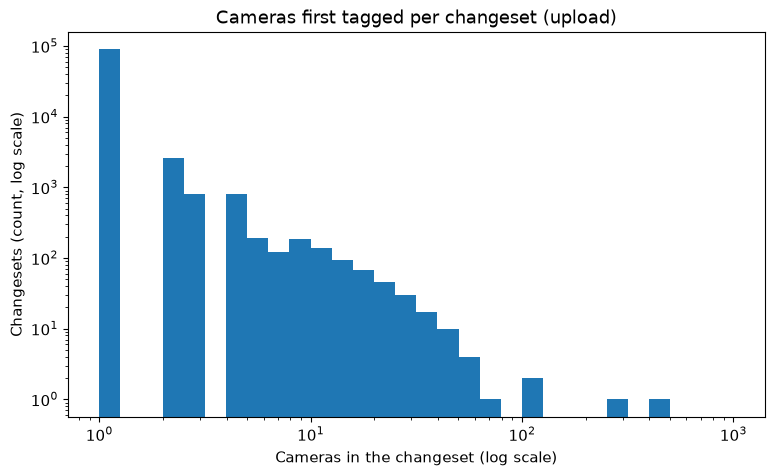

Changesets: 94,928   median size: 1   mean: 1.19   max: 430
Single-camera changesets: 94.7%   cameras in single-camera changesets: 79.9%


In [34]:
# Changeset size: how many cameras were first tagged in each upload.
fig, ax = plt.subplots()
ax.hist(changeset_sizes["cameras_in_changeset"].to_numpy(), bins=np.logspace(0, 3, 31), color="tab:blue")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_title("Cameras first tagged per changeset (upload)")
ax.set_xlabel("Cameras in the changeset (log scale)")
ax.set_ylabel("Changesets (count, log scale)")
plt.show()
sizes = changeset_sizes["cameras_in_changeset"]
print(f"Changesets: {sizes.len():,}   median size: {sizes.median():.0f}   mean: {sizes.mean():.2f}   max: {sizes.max()}")
print(f"Single-camera changesets: {(sizes == 1).mean() * 100:.1f}%   cameras in single-camera changesets: {sizes.filter(sizes == 1).sum() / row_count * 100:.1f}%")

**Observation (center and spread):** The typical upload tags one camera: the median changeset size is 1 (mean 1.19), and 94.7% of changesets contain a single camera.

**Observation (skew and outliers):** The distribution is extremely right-skewed: a few uploads tag hundreds (maximum 430). Even so, 79.9% of all cameras came in single-camera uploads.

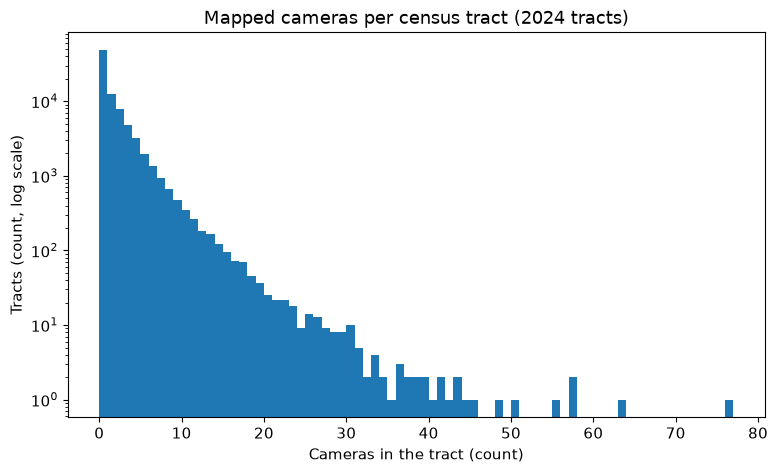

Tracts: 84,401   with 0 cameras: 58.1%   mean: 1.33   median: 0   max: 76


In [35]:
# Cameras per tract, zero-camera tracts included. Log y-axis: most tracts have 0.
fig, ax = plt.subplots()
ax.hist(tract_cameras["cameras"].to_numpy(), bins=np.arange(0, tract_cameras["cameras"].max() + 2), color="tab:blue")
ax.set_yscale("log")
ax.set_title("Mapped cameras per census tract (2024 tracts)")
ax.set_xlabel("Cameras in the tract (count)")
ax.set_ylabel("Tracts (count, log scale)")
plt.show()
per_tract = tract_cameras["cameras"]
print(f"Tracts: {per_tract.len():,}   with 0 cameras: {(per_tract == 0).mean() * 100:.1f}%   mean: {per_tract.mean():.2f}   median: {per_tract.median():.0f}   max: {per_tract.max()}")

**Observation:** Of 84,401 tracts, 58.1% have no mapped camera; the median is 0, the mean 1.33 and the maximum 76. The distribution is strongly right-skewed.

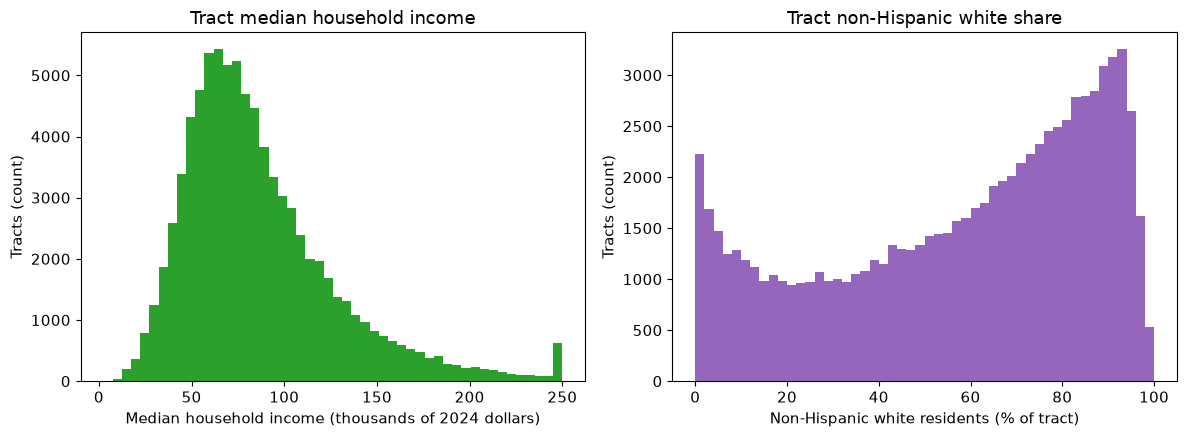

Income median: $77,449   tracts at the $250,000 cap: 555
White share median: 65.1%   middle 50%: 35.5% to 83.3%


In [36]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].hist(tract_cameras["median_income"].drop_nulls().to_numpy() / 1000, bins=50, color="tab:green")
axes[0].set_title("Tract median household income")
axes[0].set_xlabel("Median household income (thousands of 2024 dollars)")
axes[0].set_ylabel("Tracts (count)")
axes[1].hist(tract_cameras["white_share_pct"].drop_nulls().to_numpy(), bins=50, color="tab:purple")
axes[1].set_title("Tract non-Hispanic white share")
axes[1].set_xlabel("Non-Hispanic white residents (% of tract)")
axes[1].set_ylabel("Tracts (count)")
plt.tight_layout()
plt.show()
income_values = tract_cameras["median_income"].drop_nulls()
white_values = tract_cameras["white_share_pct"].drop_nulls()
print(f"Income median: ${income_values.median():,.0f}   tracts at the $250,000 cap: {(income_values == 250000).sum():,}")
print(f"White share median: {white_values.median():.1f}%   middle 50%: {white_values.quantile(0.25):.1f}% to {white_values.quantile(0.75):.1f}%")

**Observation:** The secondary features: median income is right-skewed (median $77,449, 555 tracts at the $250,000 cap), and white share is left-skewed (median 65.1%, middle half 35.5% to 83.3%).

## Step 4: Relationships

Comparisons across groups use cameras per 10,000 residents (total cameras divided by total
population in the group), not raw counts. Tracts with population 0 or no income estimate are left out.

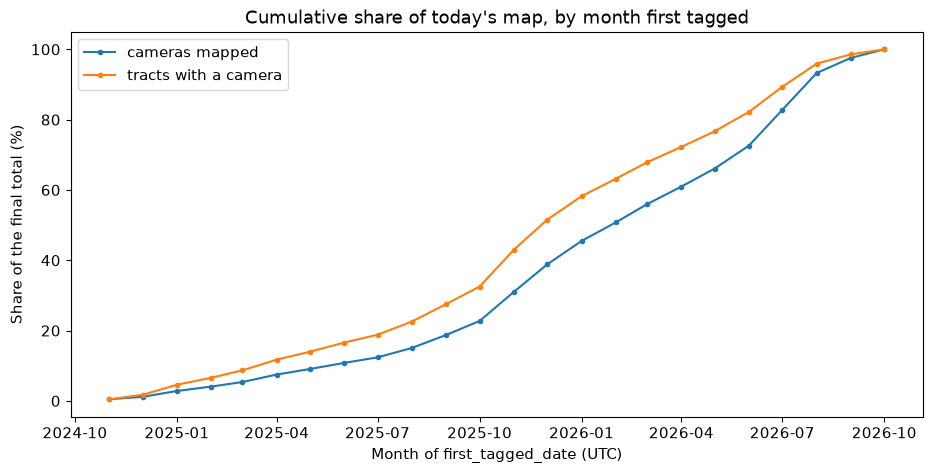

Tracts with a camera by Oct 2026: 35,337


month,cameras_pct,tracts_pct
"datetime[μs, UTC]",f64,f64
2025-12-01 00:00:00 UTC,38.8,51.6


In [37]:
# Time and place together: share of today's cameras mapped by each month, and
# share of today's camera tracts that had at least one camera by then.
first_month_per_tract = (
    cameras_located.group_by("GEOID")
    .agg(pl.col("tagged").min().dt.truncate("1mo").alias("month"))
    .group_by("month").len("new_tracts")
)
growth = (
    cameras_located.group_by(pl.col("tagged").dt.truncate("1mo").alias("month")).len("new_cameras")
    .join(first_month_per_tract, on="month", how="left")
    .fill_null(0)
    .sort("month")
    .with_columns(
        (pl.col("new_cameras").cum_sum() / pl.col("new_cameras").sum() * 100).alias("cameras_pct"),
        (pl.col("new_tracts").cum_sum() / pl.col("new_tracts").sum() * 100).alias("tracts_pct"),
    )
)
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(growth["month"].to_list(), growth["cameras_pct"].to_list(), marker="o", markersize=3, label="cameras mapped")
ax.plot(growth["month"].to_list(), growth["tracts_pct"].to_list(), marker="o", markersize=3, label="tracts with a camera")
ax.set_title("Cumulative share of today's map, by month first tagged")
ax.set_xlabel("Month of first_tagged_date (UTC)")
ax.set_ylabel("Share of the final total (%)")
ax.legend()
plt.show()
print(f"Tracts with a camera by Oct 2026: {first_month_per_tract['new_tracts'].sum():,}")
growth.filter(pl.col("month") == pl.datetime(2025, 12, 1, time_zone="UTC")).select("month", pl.col("cameras_pct", "tracts_pct").round(1))

**Observation:** By December 2025, 38.8% of today's cameras had been tagged, but 51.6% of the 35,337 tracts that now have a camera already had one. The tract line stays above the camera line every month.

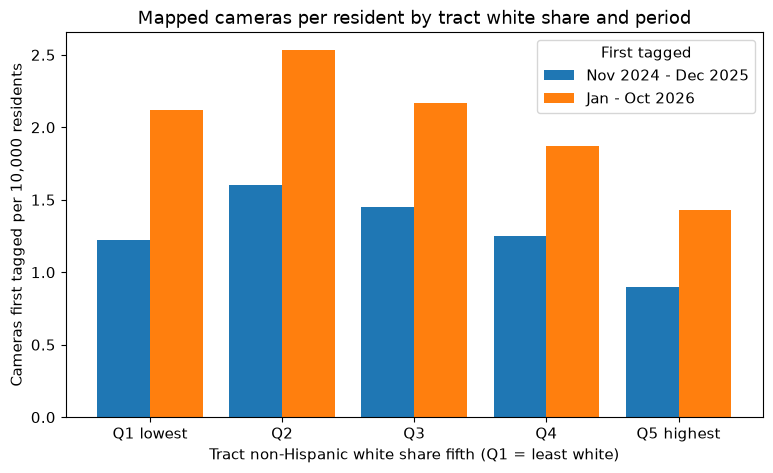

quintile,min,max,per_10k_before_2026,per_10k_2026
cat,f64,f64,f64,f64
"""Q1 lowest""",0.0,27.2,1.22,2.12
"""Q2""",27.2,55.0,1.6,2.53
"""Q3""",55.0,73.2,1.45,2.17
"""Q4""",73.2,86.3,1.25,1.87
"""Q5 highest""",86.3,100.0,0.9,1.43


In [38]:
# Fifths (quintiles) of tracts by a characteristic; rates per mapping period.
rate_tracts = tract_cameras.filter(pl.col("population") > 0)
QUINTILE_LABELS = ["Q1 lowest", "Q2", "Q3", "Q4", "Q5 highest"]


def rates_by_quintile(table: pl.DataFrame, column_name: str) -> pl.DataFrame:
    """Cameras per 10,000 residents, by quintile of column_name and mapping period."""
    return (
        table.filter(pl.col(column_name).is_not_null())
        .with_columns(pl.col(column_name).qcut(5, labels=QUINTILE_LABELS).alias("quintile"))
        .group_by("quintile")
        .agg(
            pl.col(column_name).min().round(1).alias("min"),
            pl.col(column_name).max().round(1).alias("max"),
            pl.col("population").sum(),
            pl.col("cameras_before_2026").sum(),
            pl.col("cameras_2026").sum(),
        )
        .with_columns(
            (pl.col("cameras_before_2026") / pl.col("population") * 10_000).round(2).alias("per_10k_before_2026"),
            (pl.col("cameras_2026") / pl.col("population") * 10_000).round(2).alias("per_10k_2026"),
        )
        .sort("quintile")
    )


def plot_period_bars(rates: pl.DataFrame, title: str, xlabel: str) -> None:
    """Side-by-side bars of the two mapping periods for each quintile."""
    positions = np.arange(rates.height)
    fig, ax = plt.subplots()
    ax.bar(positions - 0.2, rates["per_10k_before_2026"], width=0.4, label=PERIOD_LABELS[0])
    ax.bar(positions + 0.2, rates["per_10k_2026"], width=0.4, label=PERIOD_LABELS[1])
    ax.set_xticks(positions, rates["quintile"].cast(pl.String).to_list())
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Cameras first tagged per 10,000 residents")
    ax.legend(title="First tagged")
    plt.show()


white_rates = rates_by_quintile(rate_tracts, "white_share_pct")
plot_period_bars(white_rates, "Mapped cameras per resident by tract white share and period",
                 "Tract non-Hispanic white share fifth (Q1 = least white)")
white_rates.select("quintile", "min", "max", "per_10k_before_2026", "per_10k_2026")

**Observation:** In both periods the whitest fifth of tracts has the lowest rate (0.9 per 10,000 before 2026, 1.43 in 2026), and the 27-55% white fifth the highest (1.6 and 2.53). The 2026 wave kept the same shape at a higher level.

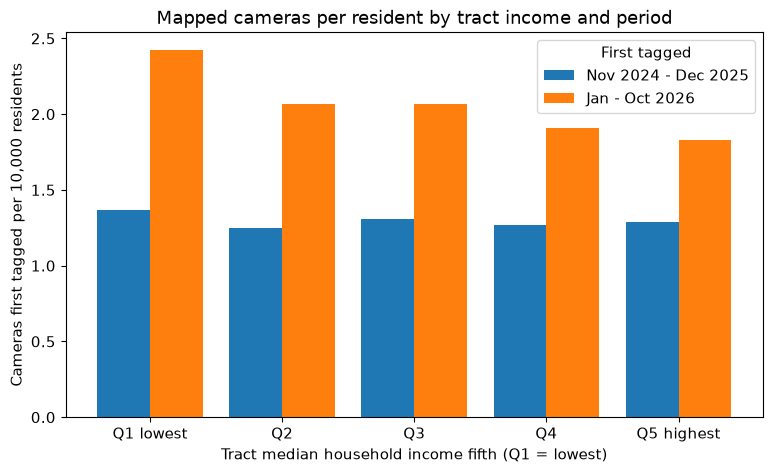

quintile,min,max,per_10k_before_2026,per_10k_2026
cat,f64,f64,f64,f64
"""Q1 lowest""",2500.0,53804.0,1.37,2.42
"""Q2""",53806.0,69588.0,1.25,2.07
"""Q3""",69591.0,86406.0,1.31,2.07
"""Q4""",86408.0,113778.0,1.27,1.91
"""Q5 highest""",113786.0,250000.0,1.29,1.83


In [39]:
income_rates = rates_by_quintile(rate_tracts, "median_income")
plot_period_bars(income_rates, "Mapped cameras per resident by tract income and period",
                 "Tract median household income fifth (Q1 = lowest)")
income_rates.select("quintile", "min", "max", "per_10k_before_2026", "per_10k_2026")

**Observation:** Before 2026 the income fifths are nearly flat (1.25 to 1.37 per 10,000). In 2026 the lowest-income fifth gained the most (2.42) and the highest the least (1.83).

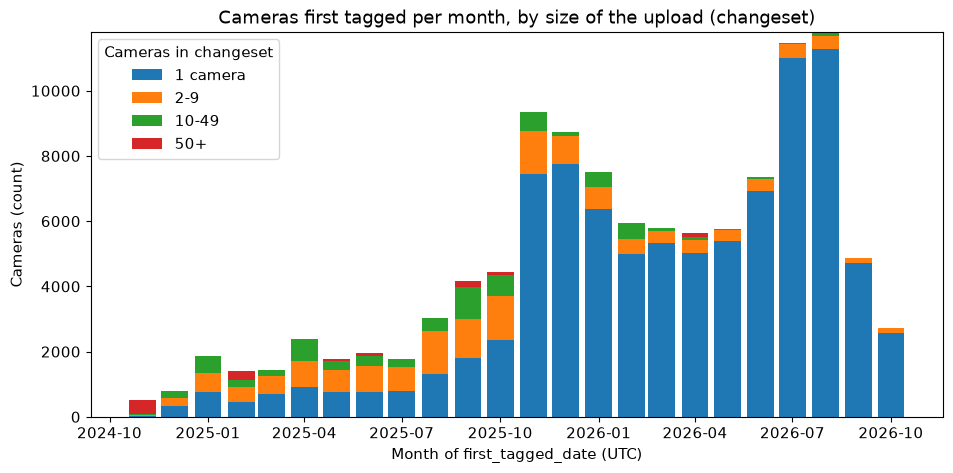

month,cameras,pct_in_uploads_of_10_plus
"datetime[μs, UTC]",u32,f64
2025-11-01 00:00:00 UTC,9345,6.2
2026-07-01 00:00:00 UTC,11457,0.3
2026-08-01 00:00:00 UTC,11807,1.0


In [40]:
# Are the monthly spikes bulk uploads? Split each month's new cameras by the
# size of the changeset that first tagged them.
SIZE_LABELS = ["1 camera", "2-9", "10-49", "50+"]
monthly_by_size = (
    history.with_columns(
        pl.when(pl.col("cameras_in_changeset") == 1).then(pl.lit(SIZE_LABELS[0]))
        .when(pl.col("cameras_in_changeset") < 10).then(pl.lit(SIZE_LABELS[1]))
        .when(pl.col("cameras_in_changeset") < 50).then(pl.lit(SIZE_LABELS[2]))
        .otherwise(pl.lit(SIZE_LABELS[3]))
        .alias("changeset_size"),
        pl.col("tagged").dt.truncate("1mo").alias("month"),
    )
    .group_by("month", "changeset_size").len("cameras")
)
months = tagged_by_month["month"].to_list()
fig, ax = plt.subplots(figsize=(11, 5))
bottom = np.zeros(len(months))
for size_label in SIZE_LABELS:
    counts = (
        tagged_by_month.select("month")
        .join(monthly_by_size.filter(pl.col("changeset_size") == size_label), on="month", how="left")
        .fill_null(0)["cameras"].to_numpy()
    )
    ax.bar(months, counts, width=25, bottom=bottom, label=size_label)
    bottom = bottom + counts
ax.set_title("Cameras first tagged per month, by size of the upload (changeset)")
ax.set_xlabel("Month of first_tagged_date (UTC)")
ax.set_ylabel("Cameras (count)")
ax.legend(title="Cameras in changeset")
plt.show()

# Share of each month's cameras that came in uploads of 10 or more, for the three busiest months.
busiest_months = tagged_by_month.sort("cameras", descending=True).head(3)["month"]
monthly_by_size.filter(pl.col("month").is_in(busiest_months.implode())).group_by("month").agg(
    pl.col("cameras").sum().alias("cameras"),
    (pl.col("cameras").filter(pl.col("changeset_size").is_in(["10-49", "50+"])).sum() / pl.col("cameras").sum() * 100).round(1).alias("pct_in_uploads_of_10_plus"),
).sort("month")

**Observation:** The spikes are not bulk imports. Uploads of 10 or more cameras supply only 6.2% of November 2025, 0.3% of July 2026 and 1.0% of August 2026, against 7.2% across all months.

In [41]:
# For comparison: the same share across all months.
all_bulk = history.filter(pl.col("cameras_in_changeset") >= 10).height / row_count * 100
print(f"Cameras in uploads of 10+ across all months: {all_bulk:.1f}%")

Cameras in uploads of 10+ across all months: 7.2%


## Step 5: So what?

**So what? (cumulative growth plot)**

- **Observation:** The map reached half of its current tracts (51.6%) when it held only 38.8% of its cameras.
- **Why it matters:** For research question 1, mapping spread to new places first and then filled in. Growth in camera counts alone would hide that.
- **Tag: In between.** Spread before density is a common pattern for volunteer maps, but the size of the gap was not known in advance.

**So what? (white share by period)**

- **Observation:** The whitest tracts have the fewest mapped cameras per resident in both periods (0.9 and 1.43).
- **Why it matters:** For research question 2, the pattern is stable across mapping waves, so it is less likely to be a quirk of one burst of mapping.
- **Tag: Unexpected.** It matches the locations notebook, but a stable pattern across periods was not assumed. It is still a group-level association, not evidence about individuals or intent.

**So what? (income by period)**

- **Observation:** The income gap appears only in 2026, when lower-income tracts gained more mapped cameras (2.42 vs 1.83).
- **Why it matters:** For research question 2, any income pattern depends on *when* mapping happened, so it may describe where mappers worked more than where cameras are.
- **Tag: Unexpected.** A flat earlier period followed by a gap was not expected.

**So what? (upload size by month)**

- **Observation:** The busiest months are made of single-camera uploads, not bulk imports.
- **Why it matters:** For research question 1, the spikes reflect many separate mapping edits, so they are real mapping activity. They are still not installs.
- **Tag: Expected.** OSM discourages bulk imports, and volunteer campaigns work one camera at a time.

## Step 6: What next? and revised research questions

**What next? (cumulative growth plot):** Repeat the curves at county level, and count distinct mappers per month to see whether the spread came from new mappers or the same people travelling.

**What next? (white share by period):** Rank tracts within their own state before forming fifths, to check that the pattern is not just a difference between regions.

**What next? (income by period):** Split the 2026 income gap by state and by urban vs. rural tracts, to see whether a few city mapping campaigns drive it.

**What next? (upload size by month):** Ask an OSM mapping community (for example a regional mapping group) what happened in November 2025 and July-August 2026, such as a campaign or a new mapping app.

### Revised research questions

1. **(revised)** Where are mapped Flock cameras, and how has the map grown over time, in cameras *and* in places reached, using `first_tagged_date`? *Changed because* the map spread to new tracts faster than it added cameras, and the series cannot start before November 2024.
2. **(revised)** Is mapped camera density per resident associated with community characteristics, and is the association stable across mapping periods? *Changed because* the white-share pattern holds in both periods but the income pattern appears only in 2026.
3. **(unchanged)** Is mapped camera density associated with political voting patterns? Not tested here.
4. **(new)** What drives the mapping bursts (November 2025, July-August 2026)? *Added because* the bursts are many single-camera uploads, not bulk imports, so they reflect mapper activity worth explaining.